<a href="https://colab.research.google.com/github/zainnazeer52-star/90_days_ai_engineering/blob/main/HR_dataset_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df = pd.read_csv("/content/HR_comma_sep.csv")
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [ ]:
df.shape

(14999, 10)

In [ ]:
df.columns
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [ ]:
df.isnull().sum()

,0
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
Department,0
salary,0


In [ ]:
print(df.duplicated().sum())


3008


In [ ]:
df = df.drop_duplicates()
df.shape

(11991, 10)

In [ ]:
df['left'].value_counts()
df['left'].value_counts(normalize=True) * 100

,proportion
left,
0,83.39588
1,16.60412


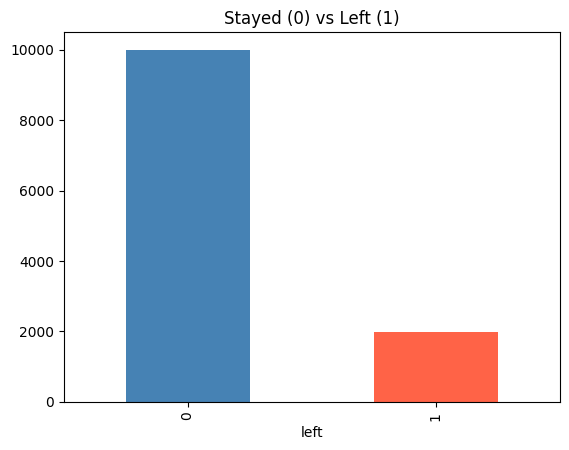

In [ ]:
import matplotlib.pyplot as plt

df['left'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'])
plt.title('Stayed (0) vs Left (1)')
plt.show()

In [ ]:
numeric_columns = ['satisfaction_level', 'last_evaluation', 'number_project',
                   'average_montly_hours', 'time_spend_company']

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    count = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    print(col, '->', count, 'outliers   fences:', lower_fence, 'to', upper_fence)

satisfaction_level -> 0 outliers   fences: -0.030000000000000027 to 1.33
last_evaluation -> 0 outliers   fences: 0.1349999999999999 to 1.295
number_project -> 0 outliers   fences: 0.0 to 8.0
average_montly_hours -> 0 outliers   fences: 28.0 to 372.0
time_spend_company -> 824 outliers   fences: 1.5 to 5.5


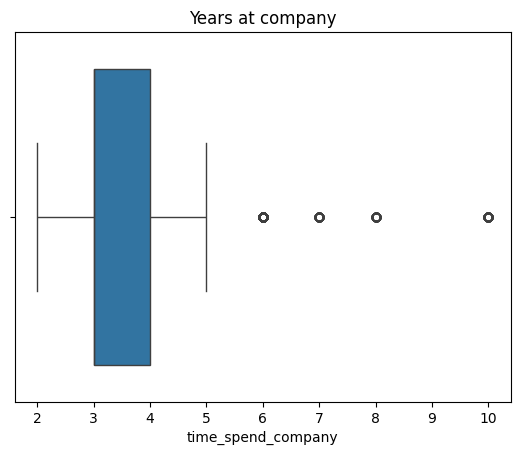

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['time_spend_company'])
plt.title('Years at company')
plt.show()

In [ ]:
df['time_spend_company'].value_counts().sort_index()

,count
time_spend_company,
2,2910
3,5190
4,2005
5,1062
6,542
7,94
8,81
10,107


In [ ]:
df.groupby('time_spend_company')['left'].mean()

,left
time_spend_company,
2,0.010653
3,0.168401
4,0.246883
5,0.453861
6,0.201107
7,0.000000
8,0.000000
10,0.000000


In [ ]:
df['overworked'] = (df['average_montly_hours'] > 250).astype(int)


In [ ]:
df['hours_per_project'] = df['average_montly_hours'] / df['number_project']

In [ ]:
df[['average_montly_hours', 'number_project', 'hours_per_project', 'overworked']].head()

,average_montly_hours,number_project,hours_per_project,overworked
0,157,2,78.500000,0
1,262,5,52.400000,1
2,272,7,38.857143,1
3,223,5,44.600000,0
4,159,2,79.500000,0


In [ ]:
print(df['overworked'].value_counts())
print(df.groupby('overworked')['left'].mean().round(2))

overworked
0    9581
1    2410
Name: count, dtype: int64
overworked
0    0.13
1    0.29
Name: left, dtype: float64


In [ ]:
df['satisfaction_group'] = pd.cut(df['satisfaction_level'], bins=[0, 0.4, 0.7, 1.0],
                                  labels=['low', 'medium', 'high'], include_lowest=True)

In [ ]:
order = {'low': 0, 'medium': 1, 'high': 2}
df['salary'] = df['salary'].map(order)
df['satisfaction_group'] = df['satisfaction_group'].astype(str).map(order)

In [ ]:
df = pd.get_dummies(df, columns=['Department'], dtype=int)
print(df.shape)   # (11991, 22)

(11991, 22)


In [ ]:
X = df.drop(columns=['left'])

non_numeric_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_cols:
    X = pd.get_dummies(X, columns=non_numeric_cols, drop_first=True, dtype=int)

y = df['left']                  # answer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (9592, 21) Test shape: (2399, 21)


In [ ]:
# Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)
print("Logistic Regression accuracy:", round(accuracy_score(y_test, log_pred) * 100, 1), "%")

Logistic Regression accuracy: 84.5 %


In [ ]:
# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_pred) * 100, 1), "%")

Random Forest accuracy: 98.6 %


In [ ]:
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred, target_names=['stayed', 'left']))

[[1997    4]
 [  30  368]]
              precision    recall  f1-score   support

      stayed       0.99      1.00      0.99      2001
        left       0.99      0.92      0.96       398

    accuracy                           0.99      2399
   macro avg       0.99      0.96      0.97      2399
weighted avg       0.99      0.99      0.99      2399



In [ ]:
importance = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importance.sort_values(ascending=False)

,0
satisfaction_level,0.261744
time_spend_company,0.160075
number_project,0.140105
average_montly_hours,0.127879
last_evaluation,0.105738
hours_per_project,0.104832
satisfaction_group,0.048972
overworked,0.017667
salary,0.009259
Work_accident,0.006276
